
[notice] A new release of pip is available: 25.1.1 -> 26.0.1
[notice] To update, run: python.exe -m pip install --upgrade pip


shape : (120, 16)
Missing values in the dataset:
AccidentNo              0
Location                0
Police Force            0
Accident Severity       0
Number of Vehicles      0
Vehicle Type            0
Speed (km/h)            0
Speed Zone              0
Number of Casualties    0
Year                    0
Date                    0
Time                    0
Occations               0
Province                0
City                    0
Street Name             0
dtype: int64

Missing values after the imputation:  0
Number of Vehicles: 21 outliers detected - capped to [0.5, 4.5]
Number of Casualties: 0 outliers detected - capped to [0.5, 4.5]
Speed_numeric: 0 outliers detected - capped to [15.0, 215.0]
Target classes: {'Bumper Accident': 0, 'Fatal Accident': 1, 'Headon Accident': 2}

Feature matrix shape: (120, 10)
Class distribution:
Accident Severity
Headon Accident    56
Bumper Accident    33
Fatal Accident     31
Name: count, dtype: int64


C:\Users\Chilli\AppData\Local\Temp\ipykernel_29496\1046508117.py:28: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df[col].fillna(df[col].median(), inplace=True)
C:\Users\Chilli\AppData\Local\Temp\ipykernel_29496\1046508117.py:32: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For e

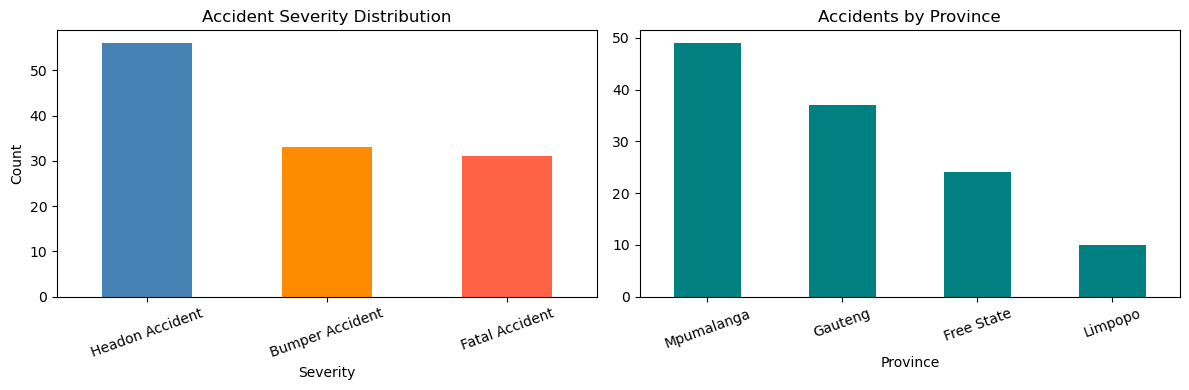

Train: 96 samples | Test: 24 samples
=== Random Forest ===
Accuracy : 1.0000
Precision: 1.0000
Recall   : 1.0000
F1-Score : 1.0000
=== XGBoost ===
Accuracy : 1.0000
Precision: 1.0000
Recall   : 1.0000
F1-Score : 1.0000


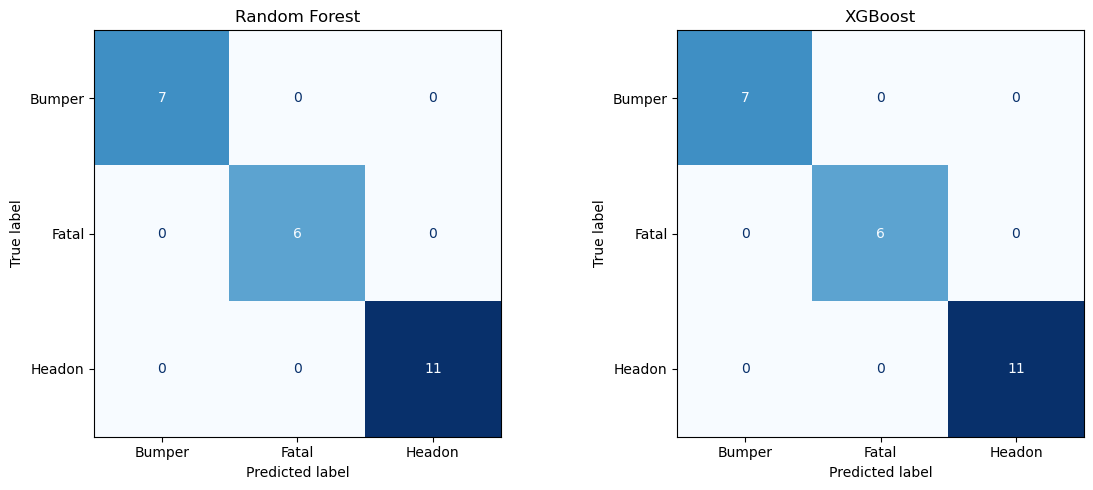

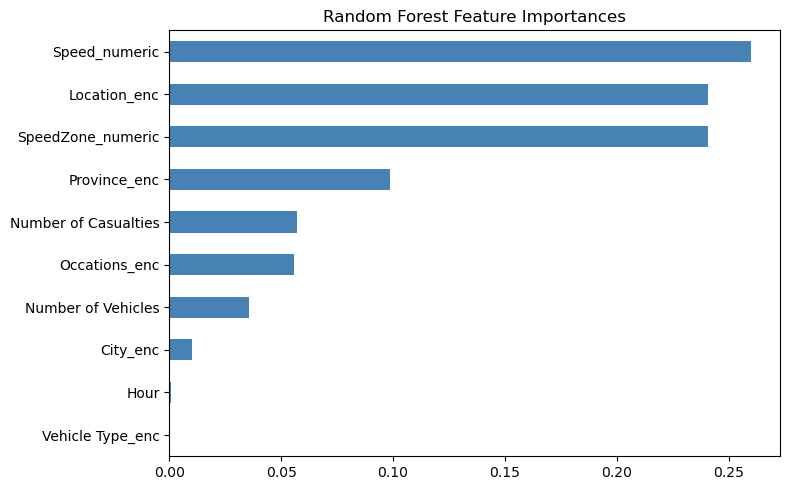

Reward table:
                     Safety Campaign  Law Enforcement  Speed Limit Reduction
Low-Freq/Good Road               2.0              1.0                    3.0
Low-Freq/Fair Road               2.0              2.0                    2.0
Low-Freq/Poor Road               1.0              3.0                    3.0
Med-Freq/Good Road               3.0              2.0                    2.0
Med-Freq/Fair Road               2.0              3.0                    2.0
Med-Freq/Poor Road               2.0              2.0                    4.0
High-Freq/Good Road              4.0              3.0                    3.0
High-Freq/Fair Road              3.0              4.0                    3.0
High-Freq/Poor Road              3.0              3.0                    5.0
Q-Learning complete.
Final epsilon: 0.0500


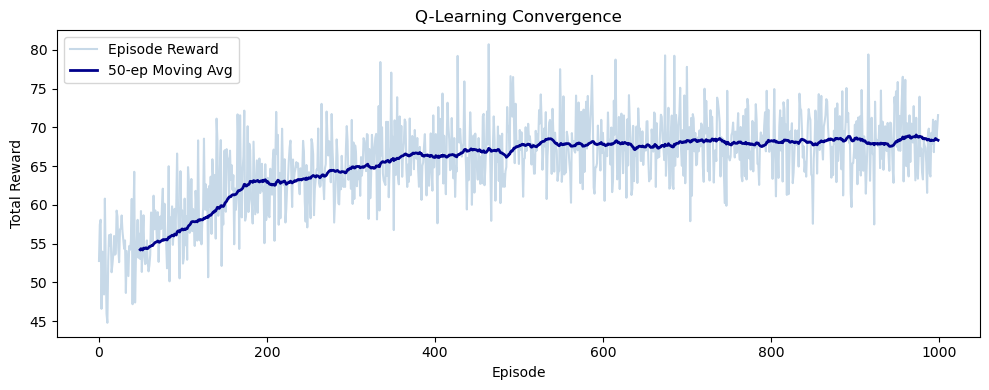

Learned Intervention Policy:
              State        Optimal Action  Q-Value
 Low-Freq/Good Road Speed Limit Reduction   34.185
 Low-Freq/Fair Road Speed Limit Reduction   33.199
 Low-Freq/Poor Road       Law Enforcement   34.011
 Med-Freq/Good Road       Safety Campaign   33.989
 Med-Freq/Fair Road       Law Enforcement   34.110
 Med-Freq/Poor Road Speed Limit Reduction   34.951
High-Freq/Good Road       Safety Campaign   35.265
High-Freq/Fair Road       Law Enforcement   35.039
High-Freq/Poor Road Speed Limit Reduction   36.062
Policy Evaluation — Intervention Distribution:
Recommend Intervention  Times Recommended
       Law Enforcement                  8
       Safety Campaign                  5
 Speed Limit Reduction                 11


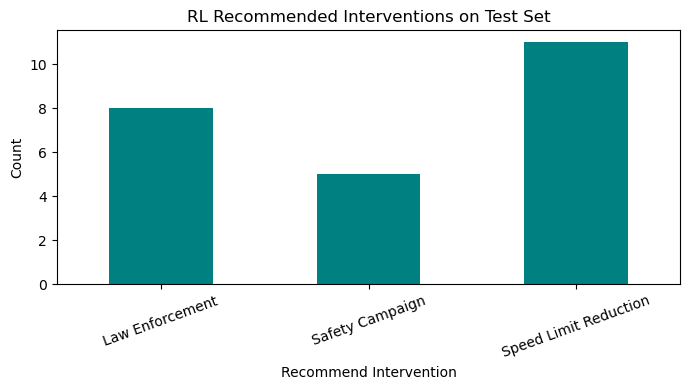

In [100]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, ConfusionMatrixDisplay
from xgboost import XGBClassifier
import sys
!{sys.executable} -m pip install xgboost
#import warnings
#warnings.filterwarnings('ignore')


#Load the dataset
df = pd.read_excel('South Africa Road Accidents Dataset - 2017.xlsx')
print('shape :', df.shape)
df.head()

#Handle missing Missing values
print('Missing values in the dataset:')
print(df.isnull().sum())

#Numerical columns and median imputation

for col in df.select_dtypes(include='number').columns:
    df[col].fillna(df[col].median(), inplace=True)

#Categorical columns and the mode imputation
for col in df.select_dtypes(include='object').columns:
    df[col].fillna(df[col].mode()[0], inplace=True)

print('\nMissing values after the imputation: ', df.isnull().sum().sum())

# Feature Engineering
df['Hour'] = pd.to_datetime(df['Time'], errors='coerce').dt.hour.fillna(0).astype(int)
df['Speed_numeric'] = df['Speed (km/h)'].str.extract(r'(\d+)').astype(float)
df['SpeedZone_numeric'] = df['Speed Zone'].str.extract(r'(\d+)').astype(float)

# Outlier Detection
for col in ['Number of Vehicles', 'Number of Casualties', 'Speed_numeric']:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1
    lower, upper = Q1 - 1.5 * IQR, Q3 + 1.5 * IQR
    outliers = df[(df[col] < lower) | (df[col] > upper)].shape[0]
    print(f'{col}: {outliers} outliers detected - capped to [{lower:.1f}, {upper:.1f}]')
    df[col] = df[col].clip(lower, upper)

# Encode Categorical Variables
le = LabelEncoder()

cat_cols = ['Location', 'Vehicle Type', 'Occations', 'Province', 'City']
for col in cat_cols:
    df[col + '_enc'] = le.fit_transform(df[col])

# Encode target
le_target = LabelEncoder()
df['Severity_enc'] = le_target.fit_transform(df['Accident Severity'])
print('Target classes:', dict(zip(le_target.classes_, le_target.transform(le_target.classes_))))

# Select Features
feature_cols = [
    'Number of Vehicles', 'Number of Casualties', 'Speed_numeric',
    'SpeedZone_numeric', 'Hour', 'Location_enc', 'Vehicle Type_enc',
    'Occations_enc', 'Province_enc', 'City_enc'
]

X = df[feature_cols]
y = df['Severity_enc']

print('\nFeature matrix shape:', X.shape)
print('Class distribution:')
print(df['Accident Severity'].value_counts())



fig, axes = plt.subplots(1, 2, figsize=(12, 4))

df['Accident Severity'].value_counts().plot(kind='bar', ax=axes[0], color=['steelblue','darkorange','tomato'])
axes[0].set_title('Accident Severity Distribution')
axes[0].set_xlabel('Severity')
axes[0].set_ylabel('Count')
axes[0].tick_params(axis='x', rotation=20)

df['Province'].value_counts().plot(kind='bar', ax=axes[1], color='teal')
axes[1].set_title('Accidents by Province')
axes[1].set_xlabel('Province')
axes[1].tick_params(axis='x', rotation=20)

plt.tight_layout()
plt.show()



# Train/test split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)
print(f'Train: {X_train.shape[0]} samples | Test: {X_test.shape[0]} samples')


# Random Forest
rf = RandomForestClassifier(n_estimators=100, random_state=42, class_weight='balanced')
rf.fit(X_train, y_train)
rf_preds = rf.predict(X_test)

print('=== Random Forest ===')
print(f'Accuracy : {accuracy_score(y_test, rf_preds):.4f}')
print(f'Precision: {precision_score(y_test, rf_preds, average="weighted"):.4f}')
print(f'Recall   : {recall_score(y_test, rf_preds, average="weighted"):.4f}')
print(f'F1-Score : {f1_score(y_test, rf_preds, average="weighted"):.4f}')


# XGBoost
xgb = XGBClassifier(n_estimators=100, random_state=42, eval_metric='mlogloss')
xgb.fit(X_train, y_train)
xgb_preds = xgb.predict(X_test)

print('=== XGBoost ===')
print(f'Accuracy : {accuracy_score(y_test, xgb_preds):.4f}')
print(f'Precision: {precision_score(y_test, xgb_preds, average="weighted"):.4f}')
print(f'Recall   : {recall_score(y_test, xgb_preds, average="weighted"):.4f}')
print(f'F1-Score : {f1_score(y_test, xgb_preds, average="weighted"):.4f}')

class_names = ['Bumper', 'Fatal', 'Headon']

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for ax, preds, title in zip(axes, [rf_preds, xgb_preds], ['Random Forest', 'XGBoost']):
    cm = confusion_matrix(y_test, preds)
    disp = ConfusionMatrixDisplay(cm, display_labels=class_names)
    disp.plot(ax=ax, colorbar=False, cmap='Blues')
    ax.set_title(title)
plt.tight_layout()
plt.show()

importances = pd.Series(rf.feature_importances_, index=feature_cols).sort_values(ascending=True)
importances.plot(kind='barh', figsize=(8, 5), color='steelblue')
plt.title('Random Forest Feature Importances')
plt.tight_layout()
plt.show()

import random

N_STATES  = 9
N_ACTIONS = 3
ACTION_NAMES = ['Safety Campaign', 'Law Enforcement', 'Speed Limit Reduction']
STATE_NAMES  = [
    'Low-Freq/Good Road', 'Low-Freq/Fair Road', 'Low-Freq/Poor Road',
    'Med-Freq/Good Road', 'Med-Freq/Fair Road', 'Med-Freq/Poor Road',
    'High-Freq/Good Road','High-Freq/Fair Road','High-Freq/Poor Road'
]

# Reward table
reward_table = np.array([
    [2, 1, 3],
    [2, 2, 2],
    [1, 3, 3],
    [3, 2, 2],
    [2, 3, 2],
    [2, 2, 4],
    [4, 3, 3],
    [3, 4, 3],
    [3, 3, 5],
], dtype=float)

print('Reward table:')
print(pd.DataFrame(reward_table, index=STATE_NAMES, columns=ACTION_NAMES))

Q = np.zeros((N_STATES, N_ACTIONS))

alpha     = 0.1
gamma     = 0.9
epsilon   = 1.0
eps_decay = 0.995
eps_min   = 0.05
n_episodes = 1000

total_rewards = []

for episode in range(n_episodes):
    state = random.randint(0, N_STATES - 1)
    ep_reward = 0

    for _ in range(20):
        if random.random() < epsilon:
            action = random.randint(0, N_ACTIONS - 1)
        else:
            action = np.argmax(Q[state])

        reward = reward_table[state][action] + np.random.normal(0, 0.1)
        next_state = random.randint(0, N_STATES - 1)

        Q[state, action] += alpha * (reward + gamma * np.max(Q[next_state]) - Q[state, action])

        ep_reward += reward
        state = next_state

    total_rewards.append(ep_reward)
    epsilon = max(eps_min, epsilon * eps_decay)

print('Q-Learning complete.')
print(f'Final epsilon: {epsilon:.4f}')

smoothed = pd.Series(total_rewards).rolling(50).mean()
plt.figure(figsize=(10, 4))
plt.plot(total_rewards, alpha=0.3, color='steelblue', label='Episode Reward')
plt.plot(smoothed, color='darkblue', linewidth=2, label='50-ep Moving Avg')
plt.title('Q-Learning Convergence')
plt.xlabel('Episode')
plt.ylabel('Total Reward')
plt.legend()
plt.tight_layout()
plt.show()

optimal_actions = np.argmax(Q, axis=1)
policy_df = pd.DataFrame({
    'State': STATE_NAMES,
    'Optimal Action': [ACTION_NAMES[a] for a in optimal_actions],
    'Q-Value': Q.max(axis=1).round(3)
})
print('Learned Intervention Policy:')
print(policy_df.to_string(index=False))

#Reinforcement learning
optimal_action = np.argmax(Q, axis=1)
policy_df = pd.DataFrame({
    'State': STATE_NAMES,
    'Optimal Action': [ACTION_NAMES[a] for a in optimal_actions],
    'Q-Value': Q.max(axis=1).round(0)
})

#Section 4
severity_to_frequency = {0: 0, 1: 2, 2: 1} #Bumper=Low, Fatal = High, Headon=Medium

results =[]
for pred in xgb_preds:
    freq_level = severity_to_frequency[pred]
    road_condition = random.randint(0, 2)
    state = freq_level * 3 + road_condition
    action = optimal_actions[state]
    results.append({
        'Predicted Severity': ['Bumper', 'Fatal','Headon'][pred],
        'RL State': STATE_NAMES[state],
        'Recommend Intervention': ACTION_NAMES[action]
    })

policy_eval = integrated_dataFrame.groupby('Recommend Intervention').size().reset_index(name='Times Recommended')
print('Policy Evaluation — Intervention Distribution:')
print(policy_eval.to_string(index=False))

policy_eval.set_index('Recommend Intervention')['Times Recommended'].plot(
    kind='bar', color='teal', figsize=(7, 4)
)
plt.title('RL Recommended Interventions on Test Set')
plt.ylabel('Count')
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

In [96]:
print(integrated_dataFrame.columns.tolist())

['Predicted Severity', 'RL State', 'Recommend Intervention']
